# Exploration du jeu de données Titanic

## 1. Contexte et objectif

Nous travaillons sur le jeu de données Titanic de la compétition Kaggle « Titanic - Machine Learning from Disaster », une référence pour apprendre la classification. Notre objectif est de prédire la survie des passagers (colonne `Survived`, 0 ou 1) : il s'agit d'une classification binaire. Nous cherchons aussi à identifier les facteurs qui ont le plus influencé leurs chances de survie.

Pour y parvenir, nous explorons d'abord le jeu de données, puis nous le nettoyons, nous définissons les variables (features) et nous les encodons. Nous entraînons ensuite trois modèles : la régression logistique, la Random Forest et XGBoost. Enfin, nous les comparons à l'aide de visualisations (matrice de confusion) et de métriques (accuracy, précision, rappel et F1).

Ce notebook se limite à l'exploration : nous constatons l'état des données et nous préparons les décisions de nettoyage, sans rien modifier.

### Description des colonnes

| Colonne | Signification |
|---|---|
| `PassengerId` | identifiant du passager |
| `Survived` | variable cible : 0 = décédé, 1 = survivant |
| `Pclass` | classe du billet : 1, 2 ou 3 |
| `Name` | nom du passager, qui contient son titre |
| `Sex` | sexe |
| `Age` | âge en années (fractionnaire pour les nourrissons) |
| `SibSp` | nombre de frères, sœurs et conjoints à bord |
| `Parch` | nombre de parents et d'enfants à bord |
| `Ticket` | numéro de billet |
| `Fare` | prix du billet |
| `Cabin` | numéro de cabine |
| `Embarked` | port d'embarquement : C = Cherbourg, Q = Queenstown, S = Southampton |

## 2. Import des bibliothèques et lecture du jeu de données

Nous importons pandas pour manipuler les données, matplotlib et seaborn pour les visualiser, puis nous lisons le fichier avec `read_csv`. Le notebook est dans `notebooks/` et le fichier dans `data/` : le chemin relatif commence donc par `..` pour remonter d'un dossier.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/dataset-titanic-6afac2fa9ddd8043393546.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Nous constatons qu'une ligne correspond à un passager et que les colonnes mélangent des variables numériques (`Age`, `Fare`), des catégories (`Sex`, `Embarked`) et du texte libre (`Name`, `Ticket`, `Cabin`). Des valeurs manquantes (`NaN`) apparaissent déjà dans `Cabin`.

## 3. Structure du jeu de données

Nous vérifions les dimensions et les types de colonnes avec `shape` et `info()`.

In [3]:
print(df.shape)
df.info()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Nous constatons que le jeu compte 891 lignes et 12 colonnes : 5 colonnes entières, 2 décimales et 5 de texte. Les types sont cohérents. `Age` est en `float` à cause des valeurs manquantes et des âges fractionnaires des nourrissons : nous le conservons tel quel. `Survived` et `Pclass` sont stockées comme des entiers, mais ce sont en réalité des catégories (une cible binaire et une classe ordonnée) : nous les traiterons comme telles lors de la modélisation.

## 4. Statistiques descriptives

Nous utilisons `describe()` pour repérer l'ordre de grandeur, la dispersion et les valeurs extrêmes des colonnes numériques.

In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Nous constatons que :
- `Age` : 714 valeurs renseignées, moyenne de 29,70 ans, médiane de 28 ans, minimum de 0,42 an (7 passagers de moins d'un an) et maximum de 80 ans.
- `Fare` : la moyenne (32,20) est bien supérieure à la médiane (14,45), l'écart type est élevé (49,69) et le maximum atteint 512,33. La distribution est donc très étirée vers les prix élevés, avec quelques valeurs extrêmes. 15 billets sont à 0, ce qui peut correspondre à des billets gratuits ou à des données manquantes.
- `SibSp` et `Parch` : la grande majorité des passagers voyage sans famille proche ou avec très peu de proches, avec quelques familles nombreuses (maximum de 8 et de 6).
- `Survived` : la moyenne correspond à la part de survivants, que nous détaillons plus loin.

Pour `Fare`, nous retiendrons que la moyenne est trompeuse : une transformation (par exemple logarithmique) pourra être utile pour la régression logistique.

## 5. Valeurs manquantes

Nous comptons les valeurs manquantes par colonne et nous calculons leur proportion, car le nombre seul ne permet pas de décider du traitement.

In [5]:
print(df.isna().sum())
print((df.isna().mean() * 100).round(1)[lambda s: s > 0])

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Age         19.9
Cabin       77.1
Embarked     0.2
dtype: float64


Nous constatons des valeurs manquantes dans trois colonnes : `Age` (177, soit 19,9 %), `Cabin` (687, soit 77,1 %) et `Embarked` (2, soit 0,2 %).

Dans le jeu de test de Kaggle, chaque passager doit recevoir une prédiction : nous ne pouvons donc pas supprimer de lignes. Par cohérence, nous traitons les valeurs manquantes par imputation ou transformation, et non par suppression, sur le train comme sur le test.

Décisions envisagées :
- `Embarked` : très peu de manquants, nous les remplacerons par la valeur la plus fréquente (le mode).
- `Age` : nous les remplacerons par la médiane, un choix que nous justifions avec la distribution des âges (section 10).
- `Cabin` : trop de manquants pour imputer. Nous étudions plus bas (section 9) l'intérêt de conserver le fait que la cabine soit renseignée ou non.

Pour `Embarked`, nous vérifions la valeur la plus fréquente.

In [6]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Nous constatons que le port `S` domine (644 passagers, soit 72,4 % des valeurs renseignées) : c'est le mode, et le remplacer ne déforme presque pas la distribution.

## 6. Variable cible : la survie

Nous comptons les survivants et nous calculons leur proportion pour savoir si les classes sont équilibrées.

In [7]:
print(df['Survived'].value_counts())
print(df['Survived'].value_counts(normalize=True).round(2))

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.62
1    0.38
Name: proportion, dtype: float64


Nous constatons que, dans le jeu d'entraînement, 342 passagers sur 891 ont survécu (soit 38 %) et 549 sont décédés (soit 62 %). Le rapport entre les deux classes est d'environ 1,6 contre 1 : les classes sont modérément réparties, et la classe minoritaire compte 342 exemples. Aucun rééchantillonnage n'est nécessaire.

Un modèle qui prédirait toujours « décédé » obtiendrait 62 % d'accuracy : c'est le seuil que nos trois modèles doivent dépasser. Nous surveillerons donc aussi la précision, le rappel et le F1, et pas seulement l'accuracy.

## 7. Doublons

Nous vérifions les lignes entièrement identiques, puis l'unicité de l'identifiant `PassengerId`.

In [8]:
print(df.duplicated().sum())
print(df["PassengerId"].is_unique)
print(df["Ticket"].nunique())

0
True
681


Nous constatons qu'il n'y a aucune ligne entièrement dupliquée et que `PassengerId` est unique : chaque ligne est un passager différent. Les numéros de billet sont en revanche partagés (681 valeurs différentes pour 891 lignes, 344 passagers partagent leur billet avec au moins un autre) : ce sont des groupes qui voyagent ensemble, pas des doublons.

## 8. Exploration de la colonne `Name`

Nous comptons les noms avec des espaces en trop, puis nous regardons les titres contenus dans les noms, qui peuvent aider à estimer l'âge et le profil des passagers.

In [9]:
print(df["Name"].nunique())
print((df["Name"] != df["Name"].str.strip()).sum())

891
2


In [10]:
titres = df["Name"].str.strip().str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
print(titres.nunique())
titres.value_counts()

17


Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Nous constatons que les 891 noms sont tous différents et que 2 d'entre eux contiennent des espaces en trop en fin de chaîne : nous les supprimerons lors du nettoyage fixe. Le titre est extractible avec une expression régulière ; il y en a 17 différents, dont beaucoup très rares. Nous les regrouperons en cinq catégories (Mr, Mrs, Miss, Master, Autre).

In [11]:
df_titre = df.copy()
df_titre["Titre"] = titres.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df_titre["Titre"] = df_titre["Titre"].where(df_titre["Titre"].isin(["Mr", "Mrs", "Miss", "Master"]), "Autre")
df_titre.groupby("Titre")["Age"].median()

Titre
Autre     48.5
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Name: Age, dtype: float64

Nous constatons que l'âge médian varie beaucoup selon le titre : 3,5 ans pour « Master » (de jeunes garçons) contre 30 ans pour « Mr ». Imputer l'âge par la médiane de son titre serait donc plus précis qu'une médiane globale. Nous comparerons les deux options lors de la préparation des données, avec la médiane calculée sur le train uniquement.

## 9. Exploration de `Pclass` et `Cabin`

Pour `Cabin`, nous avons trop de valeurs différentes pour la garder telle quelle. Nous testons donc l'idée de conserver seulement le fait qu'une cabine soit renseignée, et nous vérifions si cette variable est redondante avec `Pclass`. Ces calculs se font sur une copie.

In [12]:
df_cabine = df.copy()
df_cabine["Cabine_Renseignee"] = df_cabine["Cabin"].notna().astype(int)
print(df["Cabin"].nunique())
print(pd.crosstab(df_cabine["Pclass"], df_cabine["Cabine_Renseignee"]))
print(df_cabine["Cabine_Renseignee"].corr(df_cabine["Pclass"]).round(3))
print(df_cabine.groupby("Cabine_Renseignee")["Survived"].mean().round(3))
print(df_cabine.groupby(["Pclass", "Cabine_Renseignee"])["Survived"].mean().round(3))

147
Cabine_Renseignee    0    1
Pclass                     
1                   40  176
2                  168   16
3                  479   12
-0.726
Cabine_Renseignee
0    0.300
1    0.667
Name: Survived, dtype: float64
Pclass  Cabine_Renseignee
1       0                    0.475
        1                    0.665
2       0                    0.440
        1                    0.812
3       0                    0.236
        1                    0.500
Name: Survived, dtype: float64


Nous constatons que `Cabin` compte 147 valeurs différentes : trop pour une variable catégorielle exploitable. L'indicateur « cabine renseignée » est fortement lié à `Pclass` (corrélation de -0,73) : 176 passagers de 1ʳᵉ classe sur 216 ont une cabine renseignée, contre 12 sur 491 en 3ᵉ classe. Il garde pourtant un effet propre : le taux de survie est de 66,7 % avec une cabine renseignée contre 30,0 % sans, et l'écart persiste à classe égale (1ʳᵉ classe : 66,5 % contre 47,5 % ; 2ᵉ : 81,2 % contre 44,0 % ; 3ᵉ : 50,0 % contre 23,6 %).

Nous décidons donc de créer cette variable, puis de supprimer `Cabin`. Nous restons prudents : une corrélation n'est pas une causalité.

## 10. Visualisations

### 10.1 Matrice de corrélation

Pour visualiser les relations entre `Survived` et les autres variables, nous calculons une matrice de corrélation. Elle ne fonctionne qu'avec des colonnes numériques : nous créons donc dans une copie une colonne binaire pour `Sex` (0 = homme, 1 = femme).

In [13]:
df_corr = df.copy()
df_corr["Sexe_Binaire"] = df_corr["Sex"].map({"male": 0, "female": 1})

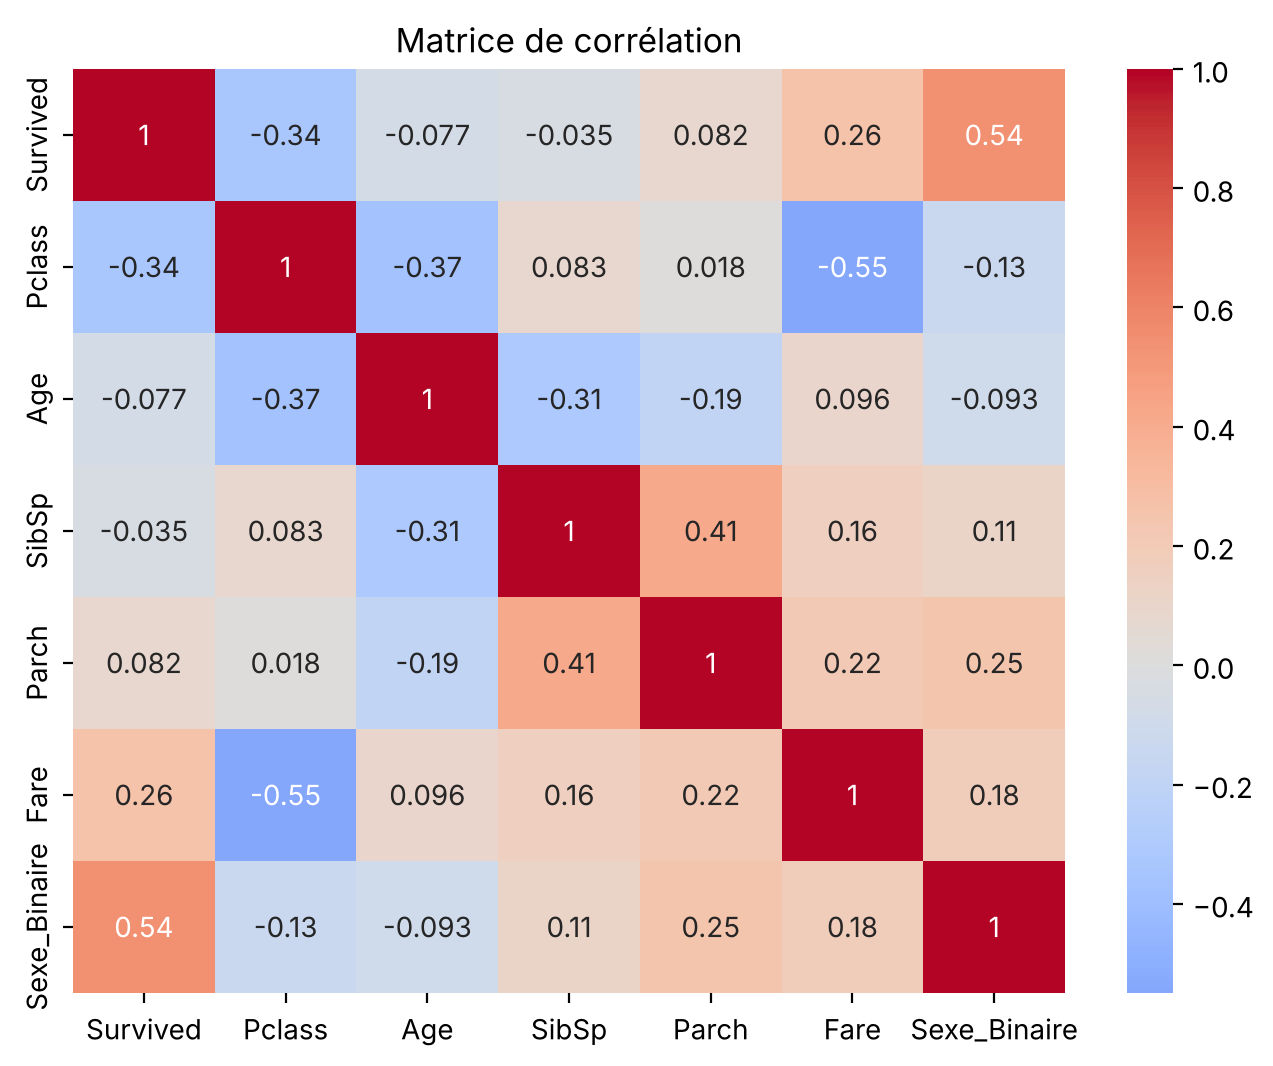

In [14]:
corr = df_corr.drop(columns="PassengerId").corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

Nous constatons que la survie est surtout liée à trois variables :
- `Sexe_Binaire` (0,54) : le lien le plus fort. Comme 1 correspond à une femme, les femmes ont davantage survécu.
- `Pclass` (-0,34) : plus le numéro de classe est élevé (3ᵉ classe), moins les passagers ont survécu.
- `Fare` (0,26) : un billet plus cher est associé à une meilleure survie, ce qui rejoint l'effet de la classe.

`Age` (-0,08), `SibSp` (-0,04) et `Parch` (0,08) ont une corrélation linéaire faible avec `Survived`. Cela ne signifie pas qu'elles n'ont aucun effet : l'âge peut agir de façon non linéaire (les enfants). De plus, `Age` compte 177 valeurs manquantes, donc sa corrélation est calculée sur les passagers dont l'âge est connu.

Nous constatons aussi des liens entre variables explicatives : `Pclass` et `Fare` (-0,55) mesurent en partie la même information, ce qui sera à surveiller pour la régression logistique ; `SibSp` et `Parch` (0,41) décrivent toutes deux la taille de la famille. Une corrélation n'est pas une causalité : elle oriente le choix des variables sans prouver leur effet.

### 10.2 Survie selon le sexe et la classe

Un diagramme en barres compare des effectifs, or les groupes n'ont pas la même taille. Nous calculons donc aussi le taux de survie de chaque groupe.

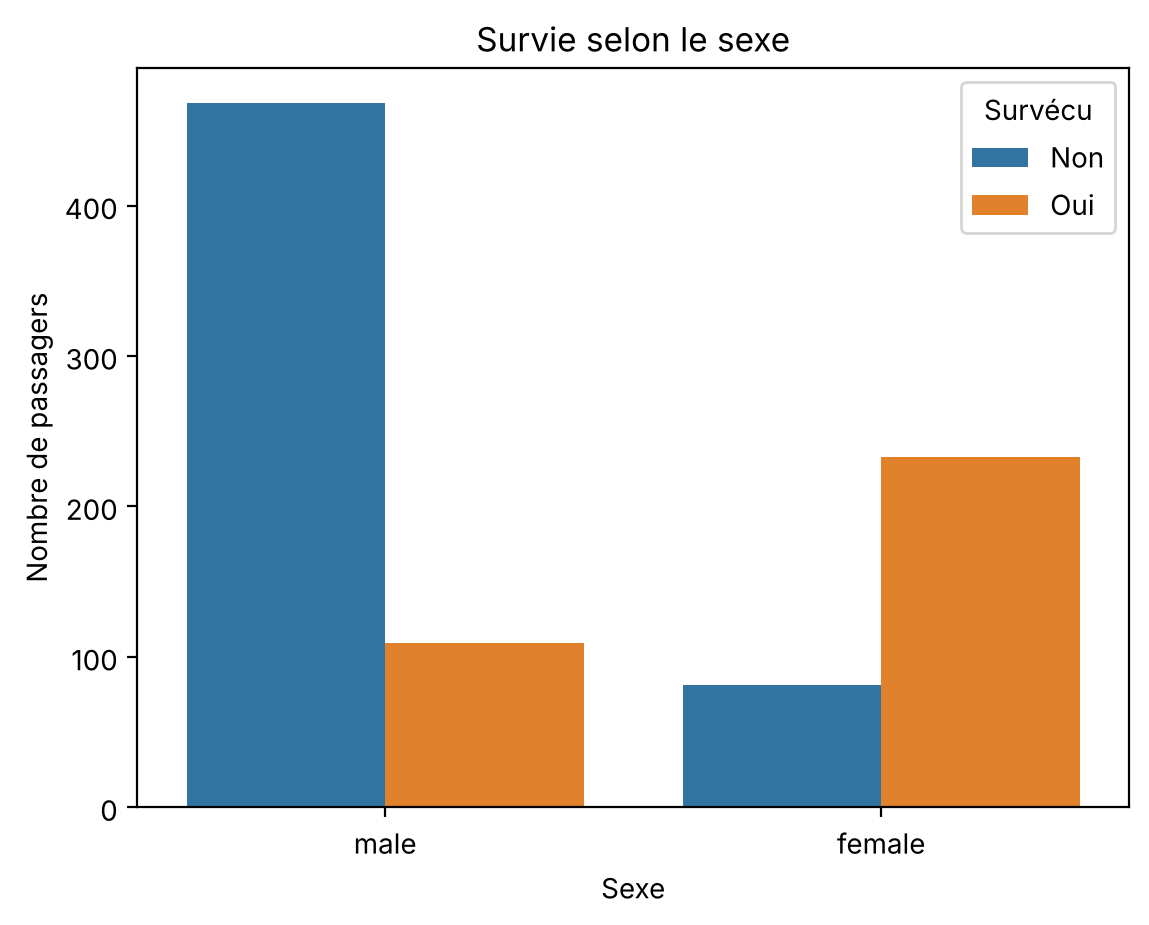

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64


In [15]:
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survie selon le sexe")
plt.xlabel("Sexe")
plt.ylabel("Nombre de passagers")
plt.legend(title="Survécu", labels=["Non", "Oui"])
plt.show()

print(df.groupby("Sex")["Survived"].mean().round(3))

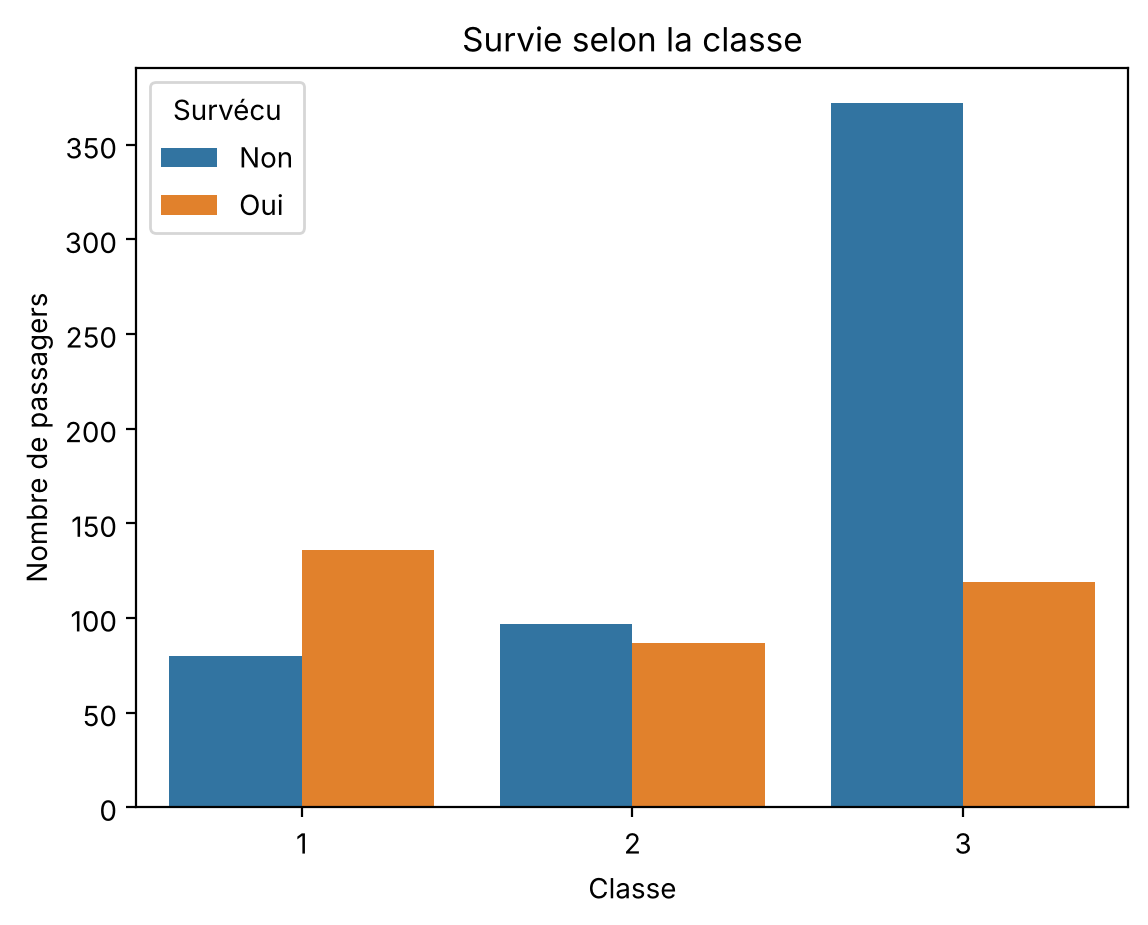

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


In [16]:
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survie selon la classe")
plt.xlabel("Classe")
plt.ylabel("Nombre de passagers")
plt.legend(title="Survécu", labels=["Non", "Oui"])
plt.show()

print(df.groupby("Pclass")["Survived"].mean().round(3))

Nous constatons que le taux de survie est de 74,2 % chez les femmes (314 passagères) contre 18,9 % chez les hommes (577 passagers). Il décroît avec la classe : 63,0 % en 1ʳᵉ classe (216 passagers), 47,3 % en 2ᵉ (184) et 24,2 % en 3ᵉ (491). La 3ᵉ classe est la plus nombreuse, d'où l'intérêt de lire les taux plutôt que les effectifs. Ces résultats confirment la matrice de corrélation : le sexe et la classe sont les deux variables les plus discriminantes.

### 10.3 Distribution des âges

Nous traçons un histogramme et nous comparons moyenne et médiane pour justifier la méthode d'imputation de `Age`.

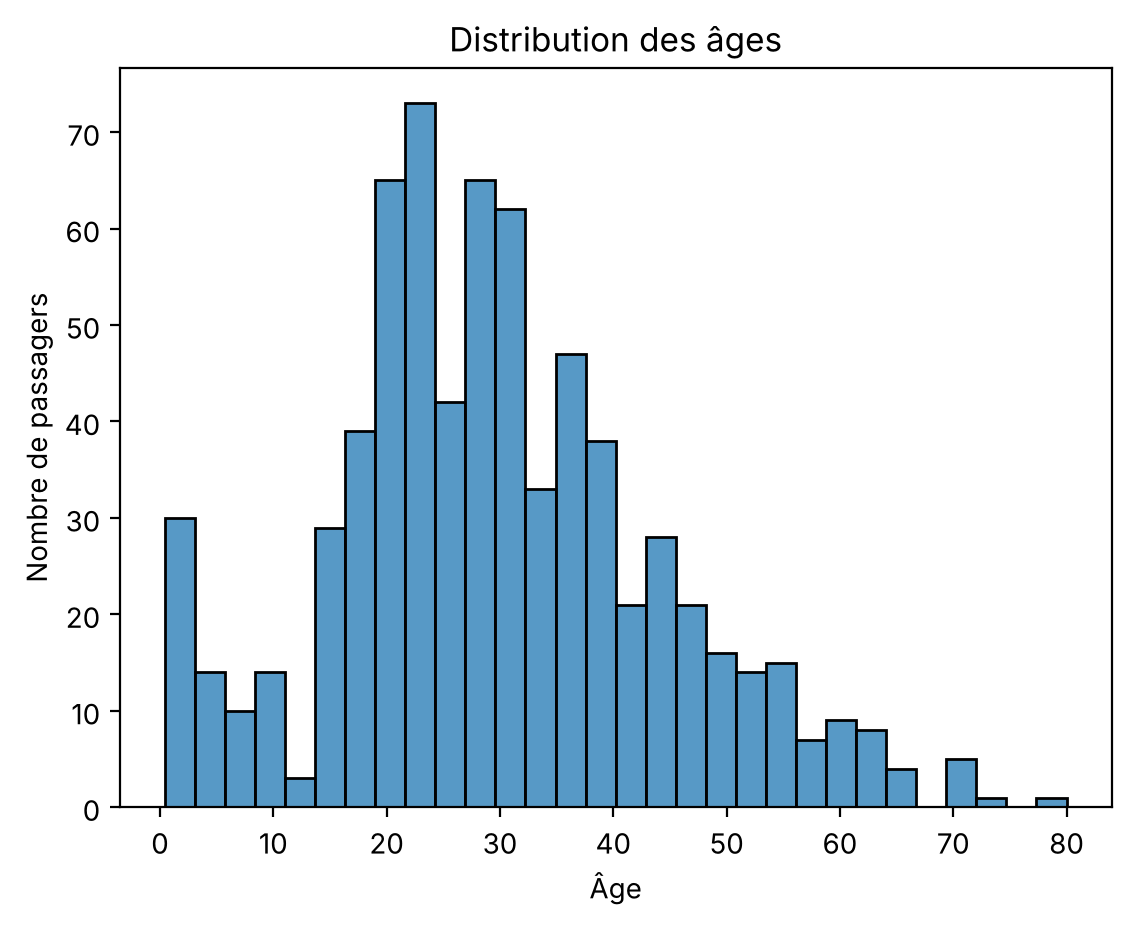

mean      29.7
median    28.0
Name: Age, dtype: float64


In [17]:
sns.histplot(data=df, x="Age", bins=30)
plt.title("Distribution des âges")
plt.xlabel("Âge")
plt.ylabel("Nombre de passagers")
plt.show()

print(df["Age"].agg(["mean", "median"]).round(2))

Nous constatons que la distribution des âges est asymétrique : la majorité des passagers a entre 20 et 40 ans environ, avec une queue vers les âges élevés (jusqu'à 80 ans) et un petit pic chez les 0 à 5 ans. L'âge médian est de 28 ans, légèrement inférieur à l'âge moyen (29,7 ans). Nous retenons la médiane pour l'imputation des valeurs manquantes, car elle est moins sensible aux valeurs extrêmes ; elle sera calculée sur le train uniquement.

## 11. Conclusion de l'exploration

Nous avons exploré 891 passagers décrits par 12 colonnes. Les données sont presque propres (aucun doublon, types cohérents), mais plusieurs valeurs manquantes et des textes libres restent à traiter. Nos décisions pour la suite :

| Colonne | Décision | Étape |
|---|---|---|
| `Name` | supprimer les espaces en trop, extraire et regrouper le titre, puis retirer la colonne | nettoyage fixe |
| `Cabin` | créer l'indicateur « cabine renseignée », puis supprimer la colonne | nettoyage fixe |
| `Ticket` | supprimer (texte libre, 681 valeurs différentes) | nettoyage fixe |
| `PassengerId` | conserver pour la soumission, exclure des variables explicatives | modélisation |
| `Age` | imputer par la médiane, calculée sur le train | pipeline |
| `Embarked` | imputer par le mode, calculé sur le train | pipeline |
| `Sex`, `Embarked`, `Titre` | encoder | pipeline |
| `Fare` | vérifier l'effet de sa forte asymétrie (valeurs extrêmes) | pipeline |

Les classes de la cible sont modérément réparties : nous n'utilisons pas de rééchantillonnage et nous évaluons les modèles avec précision, rappel et F1 en plus de l'accuracy.